In [12]:
import numpy as np
import matplotlib.pyplot as plt

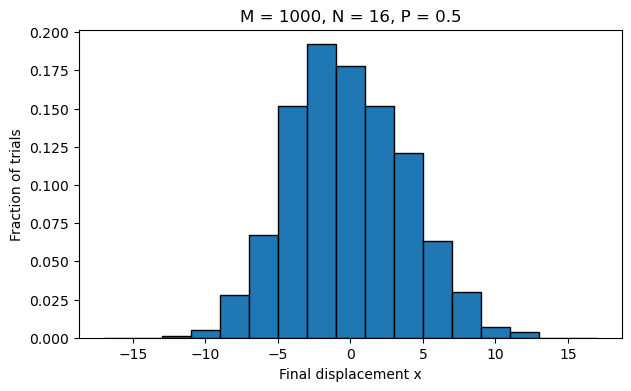

Measured mean: -0.156
Measured RMS displacement: 4.007
Measured standard deviation: 4.004


In [13]:
rng = np.random.default_rng()

def random_walk(M, N, P=0.5):
    # Each row is one trial; each column is one step.
    steps = np.where(rng.random((M, N)) < P, 1, -1)
    x = steps.sum(axis=1)

    mean = np.mean(x)
    rms = np.sqrt(np.mean(x**2))
    std = np.std(x)

    # Possible displacements are -N, -N+2, ..., N.
    bins = np.arange(-N - 1, N + 2, 2)
    plt.figure(figsize=(7, 4))
    plt.hist(x, bins=bins, weights=np.ones(M) / M,
             edgecolor="black")
    plt.xlabel("Final displacement x")
    plt.ylabel("Fraction of trials")
    plt.title(f"M = {M}, N = {N}, P = {P}")
    plt.show()

    print(f"Measured mean: {mean:.3f}")
    print(f"Measured RMS displacement: {rms:.3f}")
    print(f"Measured standard deviation: {std:.3f}")
    return x

# Initial simulation
x = random_walk(M=1000, N=16, P=0.5)

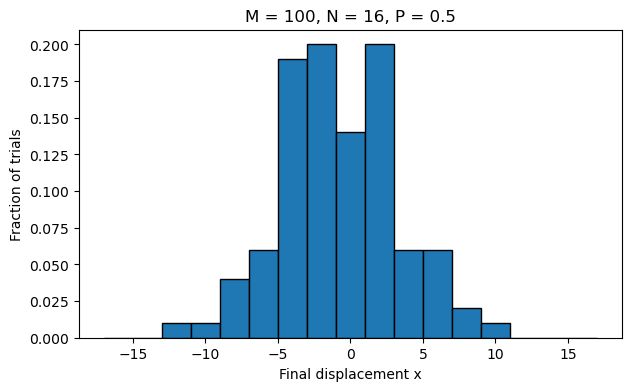

Measured mean: -0.800
Measured RMS displacement: 4.147
Measured standard deviation: 4.069


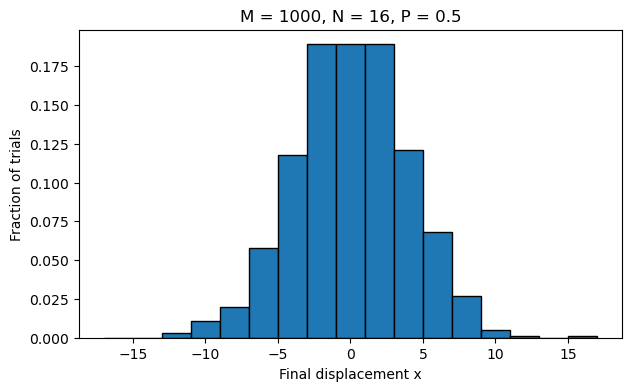

Measured mean: 0.060
Measured RMS displacement: 3.913
Measured standard deviation: 3.913


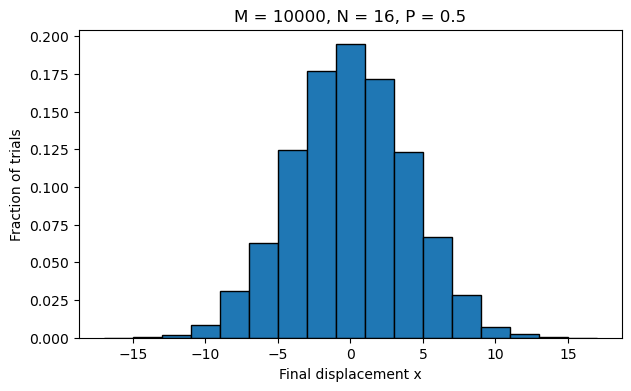

Measured mean: -0.023
Measured RMS displacement: 4.022
Measured standard deviation: 4.022


In [14]:
# A: Increase the number of trials with N fixed.
for M in [100, 1000, 10000]:
    random_walk(M=M, N=16, P=0.5)

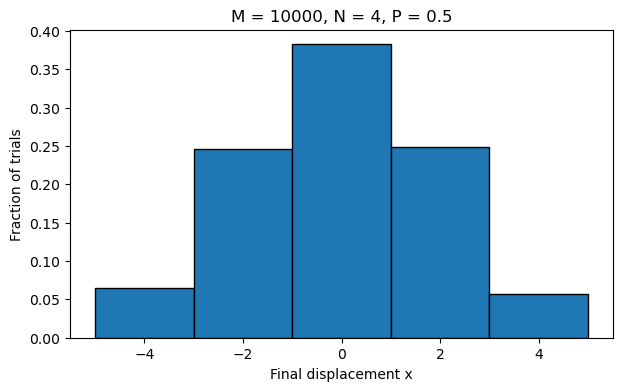

Measured mean: -0.024
Measured RMS displacement: 1.984
Measured standard deviation: 1.984


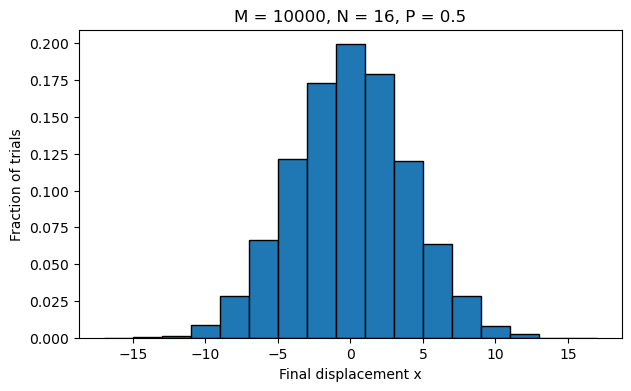

Measured mean: 0.006
Measured RMS displacement: 3.974
Measured standard deviation: 3.974


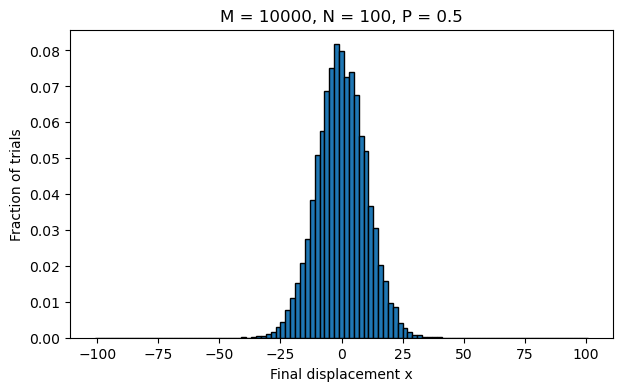

Measured mean: -0.037
Measured RMS displacement: 10.011
Measured standard deviation: 10.011


In [15]:
# B: Increase the number of steps with M fixed.
for N in [4, 16, 100]:
    random_walk(M=10000, N=N, P=0.5)

For fixed $M$ and $p = 0.5$, increasing $N$ makes the histogram wider while it stays centered near $x = 0$. The standard deviation grows as $\sqrt{N}$. The shape becomes more bell-shaped and approaches a Gaussian for large $N$. The peak becomes lower because the trials spread over more possible displacements.


N = 16, P = 0.5
Expected mean: 0.000
Expected standard deviation: 4.000
Expected RMS displacement: 4.000


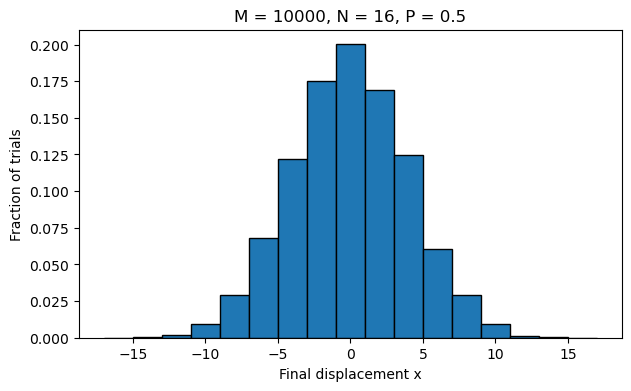

Measured mean: -0.057
Measured RMS displacement: 4.019
Measured standard deviation: 4.018
Standard error of the mean: 0.040
Measured mean within one standard error: False

N = 100, P = 0.5
Expected mean: 0.000
Expected standard deviation: 10.000
Expected RMS displacement: 10.000


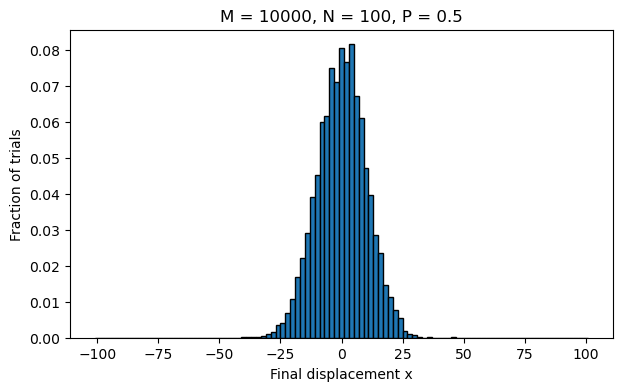

Measured mean: 0.063
Measured RMS displacement: 10.032
Measured standard deviation: 10.032
Standard error of the mean: 0.100
Measured mean within one standard error: True


In [16]:
# C and D
M = 10000

for N in [16, 100]:
    # C: For P = 0.5, the expected mean is 0 and sigma = sqrt(N).
    expected_mean = 0
    expected_std = np.sqrt(N)
    expected_rms = np.sqrt(N)
    standard_error = np.sqrt(N / M)

    print(f"\nN = {N}, P = 0.5")
    print(f"Expected mean: {expected_mean:.3f}")
    print(f"Expected standard deviation: {expected_std:.3f}")
    print(f"Expected RMS displacement: {expected_rms:.3f}")

    # D: Compare predictions with the simulation.
    x = random_walk(M=M, N=N, P=0.5)
    print(f"Standard error of the mean: {standard_error:.3f}")
    within = abs(np.mean(x)) <= standard_error
    print(f"Measured mean within one standard error: {within}")

# The measured mean fluctuates around 0.
# No finite M guarantees agreement within one standard error every time.

The simulated mean approaches zero as $M$ increases, with a typical fluctuation of $\sqrt{N/M}$. If the predicted error bars are $\pm\sqrt{N}$ from part C, about $M = 100$ trials should usually be sufficient for the measured mean to lie inside them, although no finite number guarantees this.

If the error bars instead represent one standard error of the mean, $\pm\sqrt{N/M}$, increasing $M$ does not guarantee agreement: approximately 68% of repeated measurements fall within those bars.

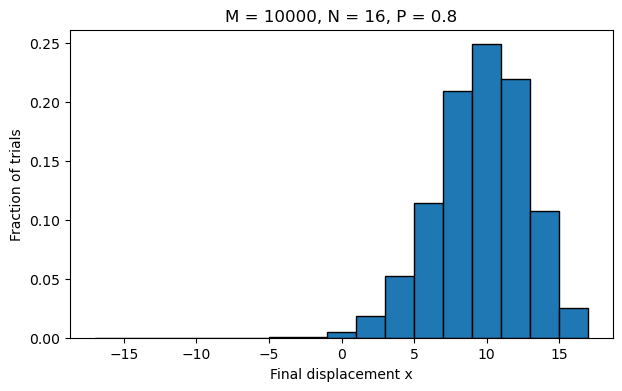

Measured mean: 9.620
Measured RMS displacement: 10.114
Measured standard deviation: 3.123
Expected mean: 9.600
Expected standard deviation: 3.200
Expected RMS displacement: 10.119
Expected most probable displacement: 10
Measured most probable displacement: 10


In [17]:
# E: Biased walk with P = 0.8 and N = 16.
N = 16
P = 0.8
x = random_walk(M=10000, N=N, P=P)

expected_mean = N * (2 * P - 1)
expected_std = 2 * np.sqrt(N * P * (1 - P))
expected_rms = np.sqrt(expected_mean**2 + expected_std**2)
# Number of positive steps follows a binomial distribution.
most_probable_x = 2 * int(np.floor((N + 1) * P)) - N
values, counts = np.unique(x, return_counts=True)
measured_mode = values[np.argmax(counts)]

print(f"Expected mean: {expected_mean:.3f}")
print(f"Expected standard deviation: {expected_std:.3f}")
print(f"Expected RMS displacement: {expected_rms:.3f}")
print(f"Expected most probable displacement: {most_probable_x}")
print(f"Measured most probable displacement: {measured_mode}")

In [18]:
### Part E

For $N = 16$, changing $p$ from $0.5$ to $0.8$ shifts the histogram toward positive displacement. It becomes narrower, with the standard deviation decreasing from $4$ to $3.2$, and becomes asymmetric with a longer tail toward smaller $x$.

The most probable displacement is $x = 10$, while the expected mean is $9.6$ and the RMS displacement is approximately $10.12$. The mean is slightly below the most probable value because of the tail toward smaller displacements. The RMS is larger than the mean because it includes both the average displacement and the spread:

$$
x_{\mathrm{rms}} = \sqrt{\langle x\rangle^2 + \sigma_x^2}
= \sqrt{9.6^2 + 3.2^2} \approx 10.12.
$$

SyntaxError: invalid syntax (2417111332.py, line 3)